In [1]:
!pip install streamlit==1.40.0 numpy==1.26.4 pandas==2.2.3 scikit-learn==1.5.2 matplotlib==3.9.2 seaborn==0.13.2

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 8.6 MB 12.7 MB/s            
     |████████████████████████████████| 18.2 MB 63.6 MB/s            
     |████████████████████████████████| 13.1 MB 65.5 MB/s            
     |████████████████████████████████| 13.4 MB 56.2 MB/s            
     |████████████████████████████████| 8.3 MB 55.5 MB/s            
     |████████████████████████████████| 294 kB 64.7 MB/s            
     |████████████████████████████████| 242 kB 62.5 MB/s            
     |████████████████████████████████| 42.7 MB 63.2 MB/s            �███▎                         | 8.4 MB 63.2 MB/s eta 0:00:01
     |████████████████████████████████| 231 kB 62.0 MB/s            
     |████████████████████████████████| 65 kB 5.9 MB/s             
     |████████████████████████████████| 320 kB 63.5 MB/s            
     |████████████████████████████████| 64 kB 5.0 MB/s             
     |██████████████████████████

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


## Bank Marketing Dataset – Data Preprocessing

### Objective
The objective of this notebook is to load, explore, clean, and preprocess
the Bank Marketing dataset before applying machine learning algorithms.

### Dataset
UCI Bank Marketing Dataset (data/bank-full.csv)

### Target Variable
y – Whether the client subscribed to a term deposit (yes/no).


The data is related with direct marketing campaigns of a Portuguese banking institution. The marketing campaigns were based on phone calls. Often, more than one contact to the same client was required, in order to access if the product (bank term deposit) would be ('yes') or not ('no') subscribed. 

In [3]:
df = pd.read_csv("../data/bank-full.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


### 1. Dataset Overview

This section examines the dimensions, columns, data types,
and basic structure of the dataset.

In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 45211
Number of columns: 17


In [5]:
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [7]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


### 2. Data Quality Assessment

This section checks for missing values, duplicate records,
and inconsistencies in the dataset.

In [8]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

Missing values in each column:


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
print("Target variable distribution:")
display(df["y"].value_counts())

print("\nTarget variable percentage:")
display(df["y"].value_counts(normalize=True) * 100)

Target variable distribution:


y
no     39922
yes     5289
Name: count, dtype: int64


Target variable percentage:


y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

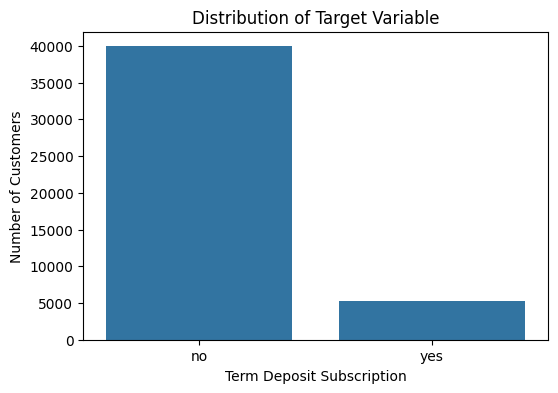

In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y")
plt.title("Distribution of Target Variable")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")
plt.show()

### 3. Data Cleaning

This section removes duplicate records and checks the cleaned dataset.

In [12]:
df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Shape after removing duplicates: (45211, 17)
Remaining duplicate rows: 0


In [13]:
target_column = "y"

X = df.drop(columns=["y", "duration"])
y = df[target_column].map({"no": 0, "yes": 1})

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("Number of input features:", X.shape[1])

print("\nTarget values:")
print(y.value_counts())

Input feature shape: (45211, 15)
Target shape: (45211,)
Number of input features: 15

Target values:
y
0    39922
1     5289
Name: count, dtype: int64


In [14]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Number of numerical features: 6
Number of categorical features: 9


In [15]:
cleaned_df = X.copy()
cleaned_df["y"] = y

cleaned_df.to_csv("../data/cleaned_bank_marketing.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final cleaned dataset shape:", cleaned_df.shape)

Cleaned dataset saved successfully!
Final cleaned dataset shape: (45211, 16)


### 4. Checking Unique Values and Data Consistency

This section examines the unique values in categorical columns
to identify unexpected or inconsistent entries.

In [16]:
for col in categorical_features:
    print(f"\nColumn: {col}")
    print(df[col].value_counts().head(15))


Column: job
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

Column: marital
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

Column: education
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

Column: default
default
no     44396
yes      815
Name: count, dtype: int64

Column: housing
housing
yes    25130
no     20081
Name: count, dtype: int64

Column: loan
loan
no     37967
yes     7244
Name: count, dtype: int64

Column: contact
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

Column: month
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403

### 5. Numerical Feature Analysis

This section visualizes the distributions of numerical features
to understand their range, spread, and possible outliers.

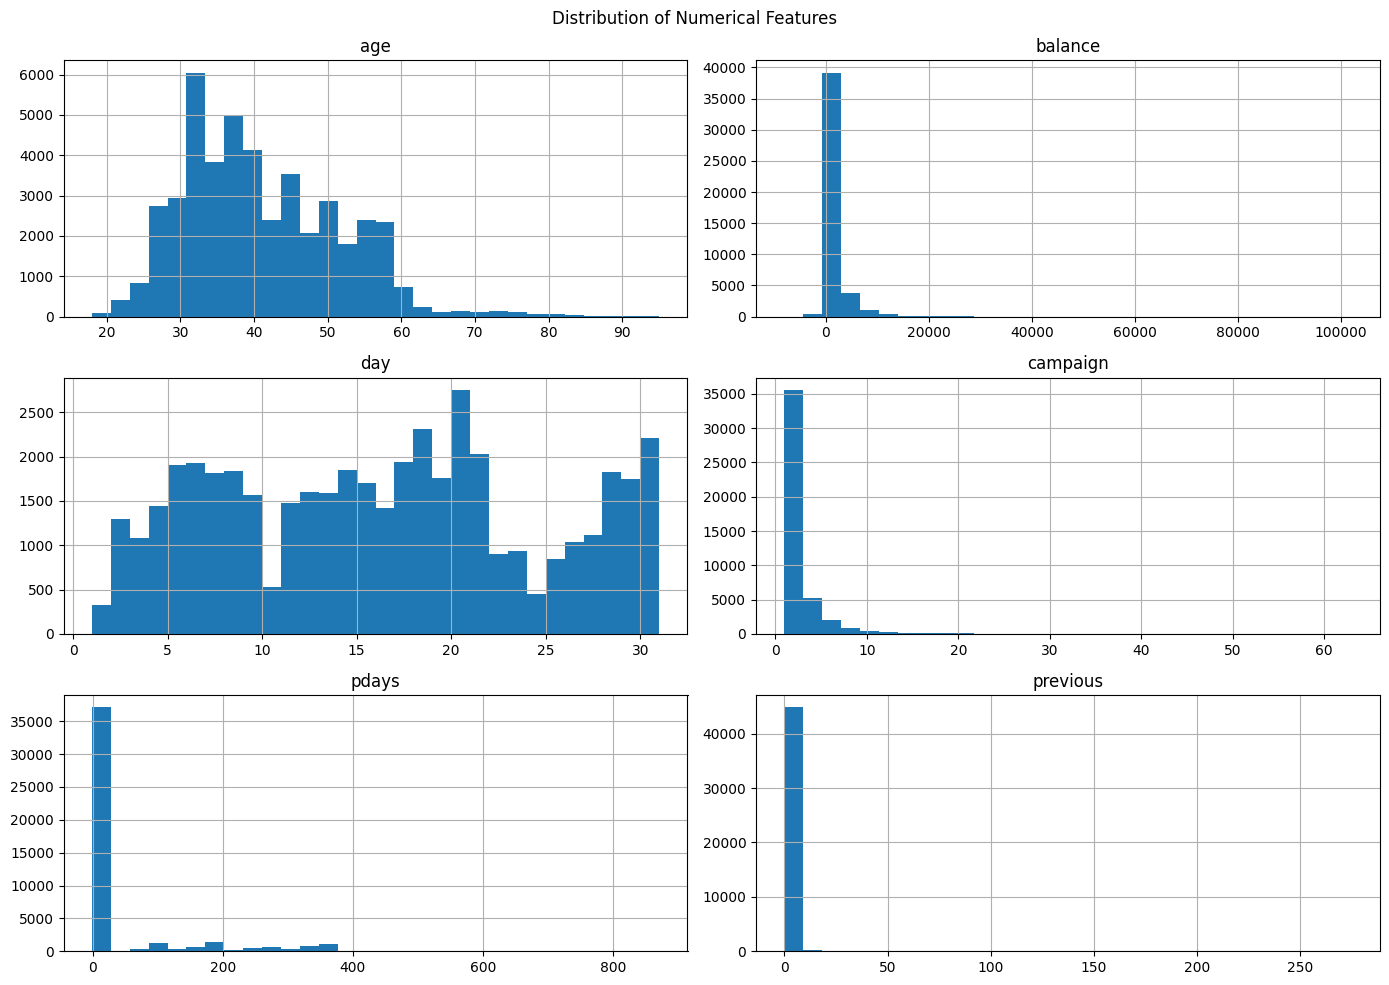

In [17]:
X[numeric_features].hist(figsize=(14, 10), bins=30)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

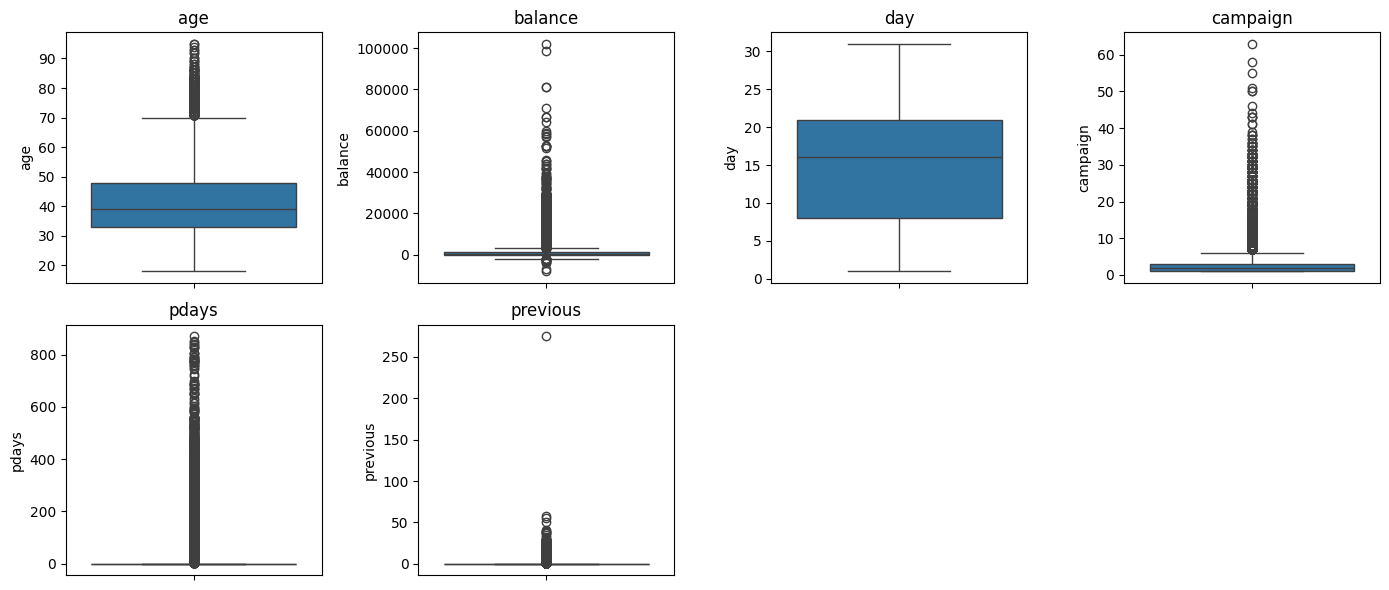

In [18]:
plt.figure(figsize=(14, 6))

for i, col in enumerate(numeric_features, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=X[col])
    plt.title(col)

plt.tight_layout()
plt.show()

### 6. Categorical Feature Analysis

This section visualizes the frequency of categories in selected
categorical features.

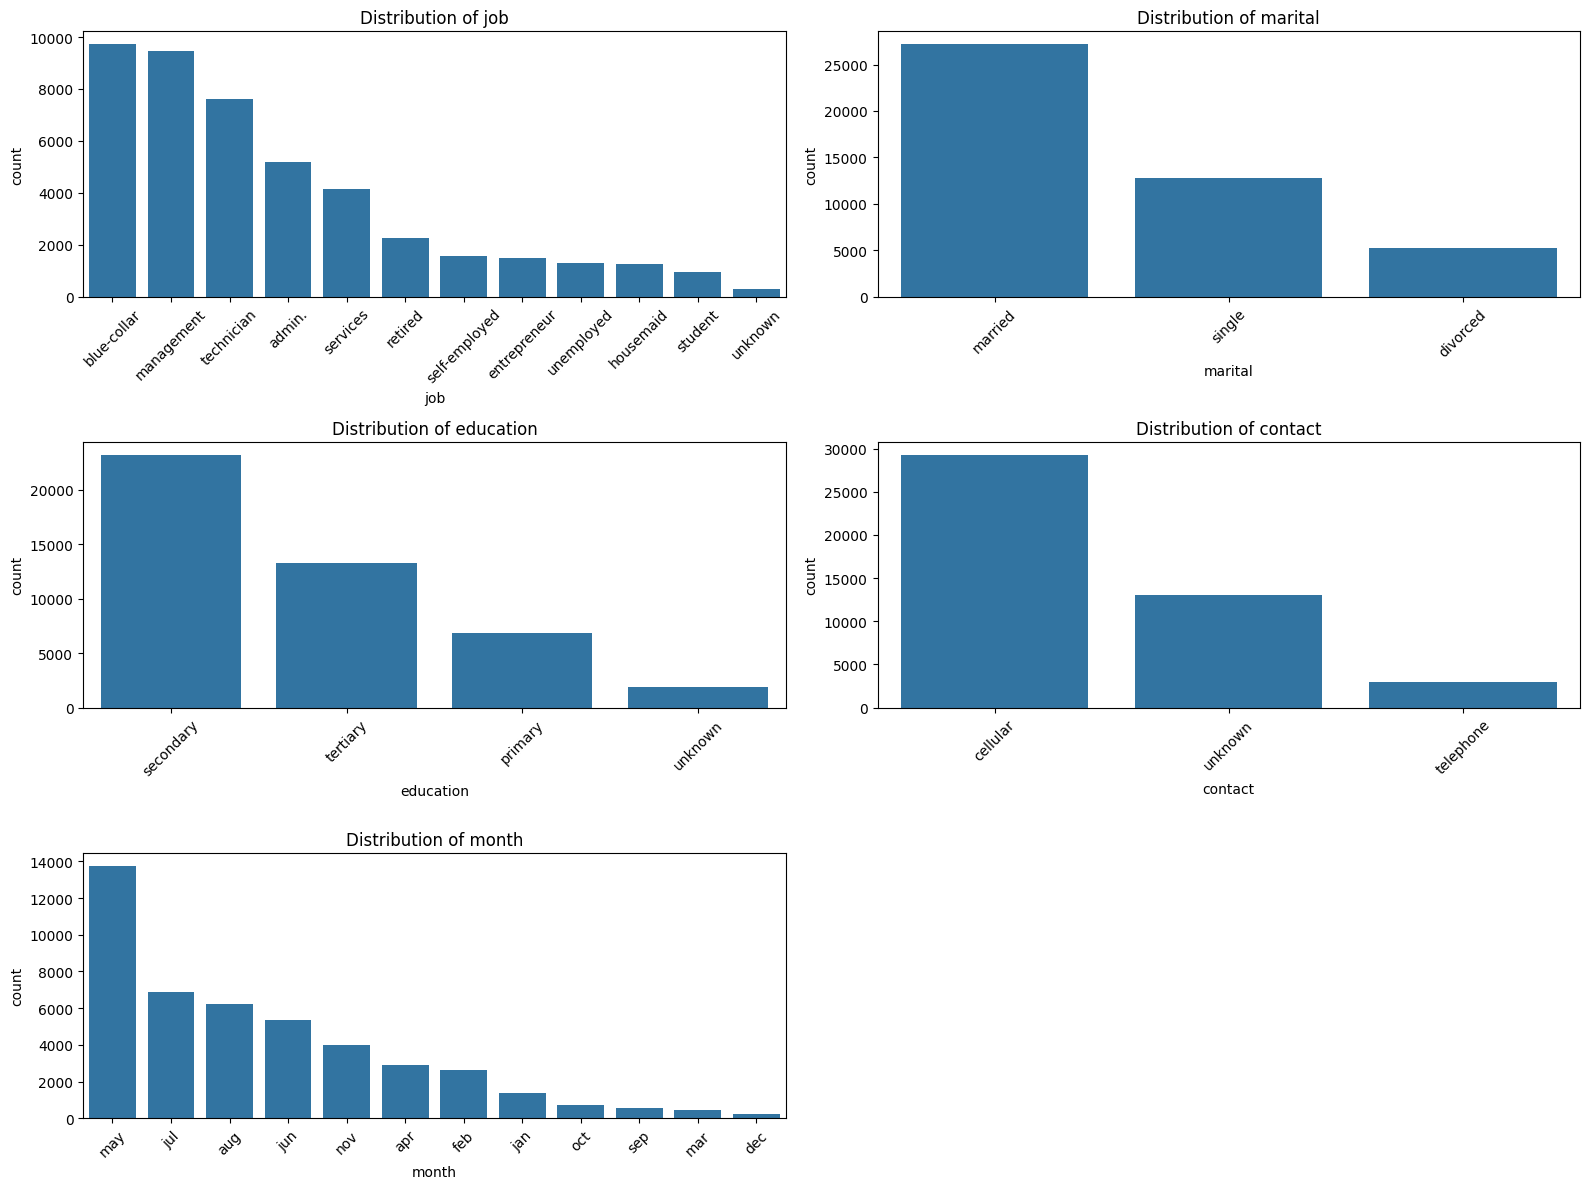

In [19]:
categorical_to_plot = ["job", "marital", "education", "contact", "month"]

plt.figure(figsize=(16, 12))

for i, col in enumerate(categorical_to_plot, 1):
    plt.subplot(3, 2, i)
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 7. Correlation Analysis

This section examines correlations between numerical features
to understand their linear relationships.

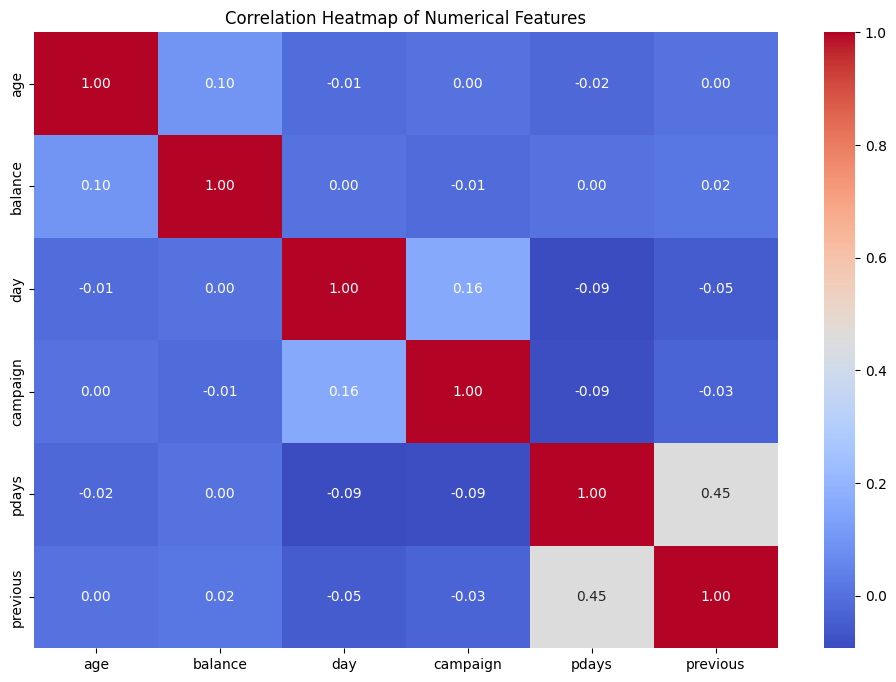

In [20]:
plt.figure(figsize=(12, 8))

correlation_matrix = X[numeric_features].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### 8. Final Cleaned Dataset

The cleaned dataset is saved for use in the machine learning
model-building notebook.

In [22]:
# Verify the cleaned dataset
print("Final dataset shape:", cleaned_df.shape)
print("\nMissing values:")
print(cleaned_df.isnull().sum().sum())

print("\nDuplicate rows:")
print(cleaned_df.duplicated().sum())

print("\nTarget distribution:")
print(cleaned_df["y"].value_counts())

# Save final dataset
cleaned_df.to_csv("../data/cleaned_bank_marketing.csv", index=False)

print("\nFinal cleaned dataset saved successfully!")

Final dataset shape: (45211, 16)

Missing values:
0

Duplicate rows:
16

Target distribution:
y
0    39922
1     5289
Name: count, dtype: int64

Final cleaned dataset saved successfully!


In [23]:
cleaned_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,0
